# S07 · RO2：前期降雨状态真的改变热浪吗？

> **Day 7 / 14** ｜ 对应论文章节 **3.6 + 4.2（Objective 2）**
>
> ⚠️ 模拟数据，结果仅用于验证流程。

---

## 学习目标

- 把「少雨→更多热浪」写成一个**有明确估计量**的统计陈述
- 知道为什么这里**不能**直接用卡方检验
- 实现保季节性的**置换检验**（permutation test）
- 用 BH-FDR 控制 30 次检验的多重比较
- 把结果写成一句能通过审稿的话

---

## 1. 先写清楚要估计什么

模棱两可的表述：

> ❌ 「前期干旱会加剧热浪。」

可检验的表述：

> ✅ **H0**：在给定日历日的前提下，事件起始日的分布与前期状态无关。
> **H1**：事件更倾向发生在 dry 状态下。
>
> 估计量：**相对风险**
> $$\mathrm{RR}=\frac{P(\text{onset}\mid \text{dry})}{P(\text{onset}\mid \text{wet})}
> =\frac{n_{\text{onset,dry}}/n_{\text{dry days}}}{n_{\text{onset,wet}}/n_{\text{wet days}}}$$
>
> `RR = 1` 表示无关；`RR = 2` 表示干前期下热浪起始的日均概率翻倍。

> 📌 **注意分母是「天」不是「事件」。** 用事件数比值会忽略干湿天数本身的比例差异 —— S06 里 dry 只占 30% 的日子，如果用事件比例直接比较，会人为压低 RR。

---

## 2. 加载

In [1]:
for (p in c("00_setup.R", "notebooks/00_setup.R", "../00_setup.R")) {
  if (file.exists(p)) { source(p); break }
}


[00_setup.R] 已加载
  项目根目录 : C:/Users/User/Desktop/Jz/UTM/UGRP
  基准期     : 1985-2014
  阈值       : 90百分位, ±7天滑窗
  事件规则   : 最短 3 天, 合并间隔 ≤ 2 天
  干/湿切点  : ARP < 30 / > 50


In [2]:
d  <- load_clean_daily()
ev <- load_catalogue()

# 逐站构建「日 → 状态」面板（有缓存，第二次几秒）
panel_file <- file.path(PATHS$mres, "panel_daily_state.rds")
if (file.exists(panel_file)) {
  panel <- readRDS(panel_file)
} else {
  panel <- do.call(rbind, lapply(sort(unique(d$station)), function(st) {
    s <- d[d$station == st, ]
    a <- antecedent_series(s)
    a[, c("station", "date", "state", "arp", "cdd")]
  }))
  saveRDS(panel, panel_file)
}

panel$doy  <- as.integer(format(panel$date, "%j"))
panel$year <- as.integer(format(panel$date, "%Y"))

cat("面板行数:", nrow(panel), "\n")
print(table(panel$state, useNA = "ifany"))

面板行数: 160600 



    dry neutral     wet    <NA> 
  47992   32083   80345     180 


---

## 3. 一个格子的手工计算

先在一个格子上把公式走一遍，再批量跑。

In [3]:
STATION <- "Kuantan"
DEFN    <- "Tmax"

p <- panel[panel$station == STATION, ]
o <- ev[ev$station == STATION & ev$defn == DEFN & !is.na(ev$state), ]

n_dry <- sum(p$state == "dry", na.rm = TRUE)
n_wet <- sum(p$state == "wet", na.rm = TRUE)
a     <- sum(o$state == "dry")
b     <- sum(o$state == "wet")

cat(sprintf("dry 日数 %5d | 其中事件起始 %3d | P = %.4f\n", n_dry, a, a / n_dry))
cat(sprintf("wet 日数 %5d | 其中事件起始 %3d | P = %.4f\n", n_wet, b, b / n_wet))
cat(sprintf("RR = %.3f  (=%.1f%% 更高的日均起始概率)\n",
            (a / n_dry) / (b / n_wet),
            100 * ((a / n_dry) / (b / n_wet) - 1)))

dry 日数  4777 | 其中事件起始  52 | P = 0.0109


wet 日数  8036 | 其中事件起始  21 | P = 0.0026


RR = 4.166  (=316.6% 更高的日均起始概率)


In [4]:
# log-RR 的 delta method 置信区间（比 bootstrap 快，30 个格子几毫秒）
rr_ci <- function(a, n1, b, n2, z = 1.96) {
  if (any(c(a, b, n1, n2) <= 0)) return(c(NA, NA, NA))
  rr <- (a / n1) / (b / n2)
  se <- sqrt(1 / a - 1 / n1 + 1 / b - 1 / n2)
  c(estimate = rr, lower = exp(log(rr) - z * se), upper = exp(log(rr) + z * se))
}
print(round(rr_ci(a, n_dry, b, n_wet), 3))

estimate    lower    upper 
   4.166    2.513    6.906 


---

## 4. 为什么不能直接用 `chisq.test()`

`chisq.test` 假设**每个观测相互独立**。这里的「观测」是**天**，而：

1. 热浪事件本身持续 3–10 天 → 起始日不独立于邻近的日子
2. ARP 是 7 天滚动量 → 相邻两天的状态高度自相关（S06 §8 已看到）
3. 事件之间有聚类（同一季节反复发生）

**后果**：卡方会严重高估有效样本量（名义 n ≈ 16000，有效 n 可能只有几百），p 值偏小几个数量级。

In [5]:
# 演示：卡方给出的 p 值有多"乐观"
tab <- matrix(c(a, n_dry - a, b, n_wet - b), nrow = 2, byrow = TRUE)
print(suppressWarnings(chisq.test(tab)))


	Pearson's Chi-squared test with Yates' continuity correction

data:  tab
X-squared = 34.746, df = 1, p-value = 3.757e-09



> ⚠️ 上面这个 p 值**不要写进论文**。它只用来做对比。
>
> 🔍 **看数量级差**：同一个格子，卡方给到 `1e-9` 量级，§5 的置换检验只给到 `1e-3` ——
> 差了六个数量级。当效应像本例这么大（RR ≈ 4）时，两者都「显著」，结论不变；
> **当效应弱一些（RR ≈ 1.3）时，这个差别就足以让结论从「显著」翻成「不显著」。**
> 审稿人不会替你算这一步，你必须自己算。

---

## 5. 保季节性的置换检验

**核心思想**：如果前期状态对事件起始没有影响，那么某个事件起始日 `(doy, year)` 上观测到的状态，
应该和**同一日历日、其他年份**观测到的状态一样可能。

于是零分布可以这样生成：

```
对每个事件起始日 (doy_i, year_i)：
    从该 doy 的所有年份中，随机抽一个 year' → 取 state(doy_i, year')
统计「抽到 dry」的个数
重复 B = 1000 次
```

**这个零分布同时保留了**：
- 季节性（同一个 doy，不跨季节抽）
- 状态的边缘分布（每年份等权）
- 事件的年月结构（起始日固定不动）

**只破坏**：某一年的状态与实际发生的事件之间的对应关系 —— 正是我们要检验的东西。

In [6]:
perm_test_dry <- function(p, o, B = CFG$n_boot, seed = CFG$seed) {
  set.seed(seed)
  yrs <- sort(unique(p$year))
  ny  <- length(yrs)

  # M[doy, year] = 该日是否 dry
  # 闰年 12-31 的 %j 是 366，所以行数要用实际最大值，不能硬写 365
  M <- matrix(0L, max(p$doy, na.rm = TRUE), ny)
  # 用 %in% 而不是 == ：state 为 NA 时 == 得到 NA，会把 NA 写进矩阵，
  # 之后随机抽到它就让整次置换变成 NA。
  M[cbind(p$doy, match(p$year, yrs))] <- as.integer(p$state %in% "dry")

  od    <- as.integer(format(o$start_date, "%j"))
  n_obs <- sum(o$state == "dry")

  sims <- vapply(seq_len(B), function(b) {
    idx <- sample.int(ny, length(od), replace = TRUE)
    sum(M[cbind(od, idx)])
  }, integer(1))

  list(observed = n_obs, sims = sims,
       p_value = (1 + sum(sims >= n_obs)) / (1 + B),
       expected = mean(sims))
}

set.seed(CFG$seed)
pt <- perm_test_dry(p, o)

cat(sprintf("观测值 : %d 个 dry 起始\n", pt$observed))
cat(sprintf("零分布均值: %.1f\n", pt$expected))
cat(sprintf("置换 p  : %.3f\n", pt$p_value))

观测值 : 52 个 dry 起始


零分布均值: 27.8


置换 p  : 0.001


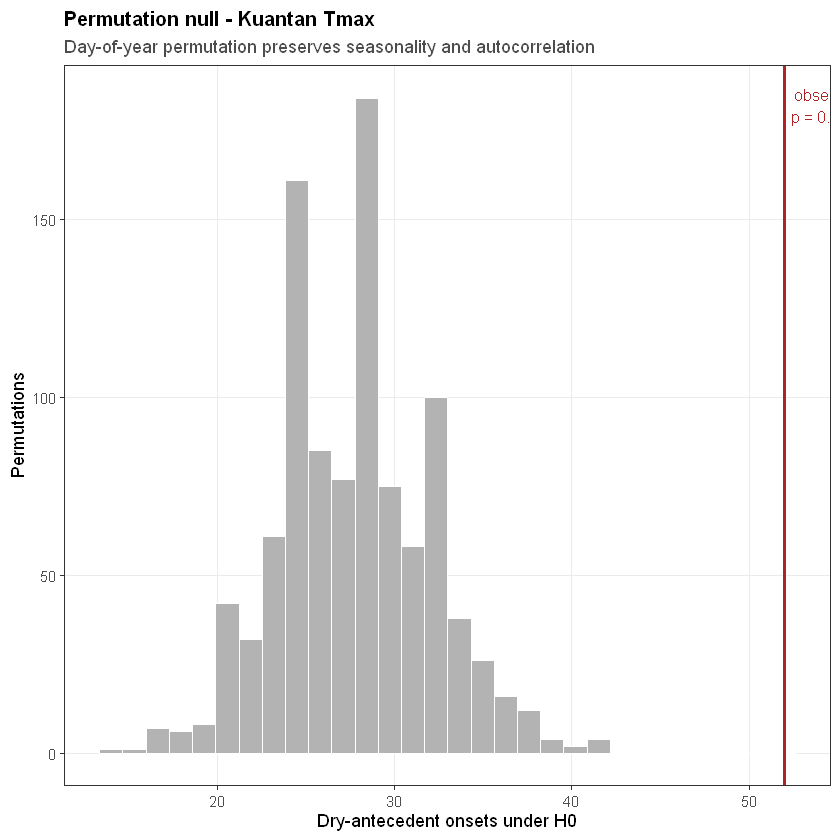

In [7]:
hist_df <- data.frame(dry_onsets = pt$sims)

p_null <- ggplot(hist_df, aes(dry_onsets)) +
  geom_histogram(bins = 30, fill = "grey70", colour = "white") +
  geom_vline(xintercept = pt$observed, colour = "firebrick", linewidth = 1) +
  annotate("text", x = pt$observed, y = Inf, vjust = 1.6, hjust = -0.1,
           label = sprintf("observed = %d\np = %.3f", pt$observed, pt$p_value),
           colour = "firebrick", size = 3.3) +
  labs(x = "Dry-antecedent onsets under H0", y = "Permutations",
       title = paste("Permutation null -", STATION, DEFN),
       subtitle = "Day-of-year permutation preserves seasonality and autocorrelation") +
  theme_paper()

save_fig(p_null, "S07_permutation_null", 6.5, 4)
p_null

> 🔍 **怎么看这张图**：红色竖线落在零分布右侧多远？
> 如果它在分布内部，说明观测到的 dry 起始数完全可以用随机波动解释 —— 高 RR 只是噪声。
>
> **零分布均值必须对得上，这是检验自己有没有写错的第一道关口。**
> 这里它约等于 `n_onset × P(dry)`：`90 × 0.298 ≈ 26.8`，实测 27.8。
> 多出来的 1 个是季节巧合（事件起始日略微更集中在旱季）。**对不上就说明置换写错了。**
>
> ⚠️ 注意零分布期望用的是「**全部**状态中日均 dry 的占比」（0.298），
> 而 RR 的分母只用 dry + wet 两类（0.373）。两者口径不同是正常的：
> 置换检验问「dry 起始数是否异常多」，RR 问「dry vs wet 的相对风险」。
> 报告时要把两者的定义都写清楚，不要让读者以为它们是同一个量。

---

## 6. 批量跑 30 个格子 + BH-FDR

In [8]:
cells <- expand.grid(station = sort(unique(panel$station)),
                     defn = DEFS, stringsAsFactors = FALSE)

res <- do.call(rbind, lapply(seq_len(nrow(cells)), function(i) {
  st <- cells$station[i]; dn <- cells$defn[i]
  p  <- panel[panel$station == st, ]
  o  <- ev[ev$station == st & ev$defn == dn & !is.na(ev$state), ]
  if (nrow(o) < 10) return(NULL)

  n_dry <- sum(p$state == "dry", na.rm = TRUE)
  n_wet <- sum(p$state == "wet", na.rm = TRUE)
  a <- sum(o$state == "dry"); b <- sum(o$state == "wet")

  ci <- rr_ci(a, n_dry, b, n_wet)
  pt <- perm_test_dry(p, o)

  data.frame(station = st, defn = dn,
             n_events = nrow(o), n_dry_onset = a, n_wet_onset = b,
             p_onset_dry = round(a / n_dry, 5), p_onset_wet = round(b / n_wet, 5),
             RR = round(ci[["estimate"]], 3),
             RR_lo = round(ci[["lower"]], 3), RR_hi = round(ci[["upper"]], 3),
             p_perm = pt$p_value)
}))

res$p_bh <- p.adjust(res$p_perm, method = "BH")
res$sig  <- ifelse(res$p_bh < 0.05, "*", "")

print(as.data.frame(res[, c("station","defn","n_events","RR","RR_lo","RR_hi",
                            "p_perm","p_bh","sig")]), row.names = FALSE)

           station  defn n_events    RR RR_lo  RR_hi      p_perm        p_bh
         Alor_Star  Tmax       99 2.904 1.864  4.525 0.000999001 0.001427144
       Bayan_Lepas  Tmax      112 2.947 1.928  4.506 0.000999001 0.001427144
 Cameron_Highlands  Tmax      112 3.149 2.039  4.863 0.000999001 0.001427144
           Chuping  Tmax       97 3.360 2.120  5.325 0.000999001 0.001427144
              Ipoh  Tmax      119 2.766 1.809  4.230 0.000999001 0.001427144
            Kluang  Tmax      105 3.118 1.988  4.889 0.000999001 0.001427144
        Kota_Bharu  Tmax       97 1.994 1.257  3.163 0.029970030 0.032110746
        Kuala_Krai  Tmax      108 3.063 1.940  4.835 0.000999001 0.001427144
           Kuantan  Tmax       90 4.166 2.513  6.906 0.000999001 0.001427144
          Langkawi  Tmax      111 3.608 2.299  5.662 0.000999001 0.001427144
         Alor_Star  Tmin       46 1.567 0.843  2.911 0.058941059 0.060973509
       Bayan_Lepas  Tmin       57 2.308 1.302  4.092 0.002997003 0.003458080

> 📌 **为什么要 BH-FDR？**
> 30 次检验，取 α = 0.05，即使全部为真零假设，平均也会有 **1.5 个假阳性**。
> BH 控制的是「被判为显著的结果里，假阳性的期望比例」≤ 5%，是气候统计的标准做法。
> **论文里必须明确写：`p` 值经 Benjamini–Hochberg 校正，`q = 0.05`。**
>
> ⚠️ 报告时同时给 `p_perm` 和 `p_bh`。前者告诉你效应有多强，后者告诉你经多重比较后还站不站得住。
>
> ⚠️ **报告的写法要注意下限**：B = 1000 时最小可达 p 是 `1/(B+1) = 0.001`。
> 表里出现好几个 `0.000999`，它们不是「恰好 0.001」，而是「**小于 0.001**」。
> 论文里写 `p < 0.001`，不要写 `p = 0.000999`。想要更细的分辨率就把 B 提到 10000。

---

## 7. 森林图：一眼看完 30 个结果

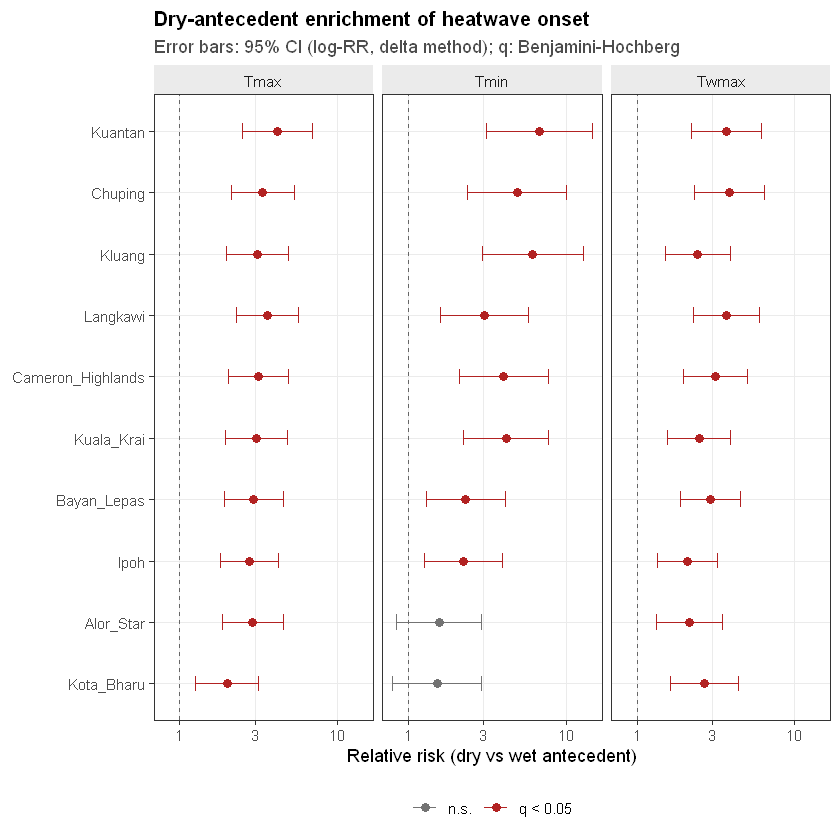

In [9]:
res$defn <- factor(res$defn, levels = DEFS)

p_forest <- ggplot(res, aes(RR, reorder(station, RR), colour = sig == "*")) +
  geom_vline(xintercept = 1, linetype = "dashed", colour = "grey40") +
  geom_errorbar(aes(xmin = RR_lo, xmax = RR_hi), width = 0.25, orientation = "y") +
  geom_point(size = 2.2) +
  facet_wrap(~defn, nrow = 1) +
  scale_x_log10() +
  scale_colour_manual(values = c(`TRUE` = "firebrick", `FALSE` = "grey45"),
                      labels = c(`TRUE` = "q < 0.05", `FALSE` = "n.s."), name = NULL) +
  labs(x = "Relative risk (dry vs wet antecedent)", y = NULL,
       title = "Dry-antecedent enrichment of heatwave onset",
       subtitle = "Error bars: 95% CI (log-RR, delta method); q: Benjamini-Hochberg") +
  theme_paper()

save_fig(p_forest, "S07_forest_rr", 8.5, 4.6)
p_forest

> 🔍 **三种可能的读法，对应三种论文写法**：
> 1. 点都在 1 右侧、CI 不跨 1 → 效应稳健，直接下结论
> 2. 点都在右侧但 CI 跨 1 → 效应方向一致但样本不足，写「方向一致的证据」
> 3. 三个定义的 RR 差异很大 → 正是本文的核心卖点（干热与湿热的驱动机制不同）

---

## 8. 状态也改变事件的「形状」吗？

RO2 不只问「会不会发生」，还问「发生了会不会更糟」。

In [10]:
attr_tab <- ev %>%
  filter(state %in% c("dry", "wet")) %>%
  group_by(station, defn) %>%
  summarise(n_dry = sum(state == "dry"), n_wet = sum(state == "wet"),
            med_dur_dry = median(duration[state == "dry"]),
            med_dur_wet = median(duration[state == "wet"]),
            med_int_dry = median(intensity[state == "dry"]),
            med_int_wet = median(intensity[state == "wet"]),
            p_dur = tryCatch(wilcox.test(duration ~ state, exact = FALSE)$p.value,
                             error = function(e) NA_real_),
            p_int = tryCatch(wilcox.test(intensity ~ state, exact = FALSE)$p.value,
                             error = function(e) NA_real_),
            .groups = "drop") %>%
  mutate(p_dur_bh = p.adjust(p_dur, "BH"),
         p_int_bh = p.adjust(p_int, "BH"))

print(as.data.frame(attr_tab), row.names = FALSE)

           station  defn n_dry n_wet med_dur_dry med_dur_wet med_int_dry
         Alor_Star  Tmax    52    31         4.0         4.0    1.550000
         Alor_Star  Tmin    19    21         3.0         3.0    2.136667
         Alor_Star Twmax    37    30         4.0         4.0    1.768215
       Bayan_Lepas  Tmax    59    33         4.0         4.0    1.500000
       Bayan_Lepas  Tmin    28    20         3.0         3.5    1.818333
       Bayan_Lepas Twmax    55    31         3.0         4.0    1.798990
 Cameron_Highlands  Tmax    58    31         4.0         3.0    1.500000
 Cameron_Highlands  Tmin    31    13         4.0         4.0    2.000000
 Cameron_Highlands Twmax    50    27         4.0         4.0    1.792612
           Chuping  Tmax    54    27         4.0         4.0    1.538333
           Chuping  Tmin    29    10         4.0         3.0    2.100000
           Chuping Twmax    48    21         4.0         4.0    1.696379
              Ipoh  Tmax    56    34         3.0   

In [11]:
# 效应方向汇总：多少个格子是 dry 条件下更长/更强？
cat("duration: dry 更长 的格子 ", sum(attr_tab$med_dur_dry > attr_tab$med_dur_wet), "/", nrow(attr_tab), "\n")
cat("intensity: dry 更强 的格子 ", sum(attr_tab$med_int_dry > attr_tab$med_int_wet), "/", nrow(attr_tab), "\n")

duration: dry 更长 的格子  6 / 30 


intensity: dry 更强 的格子  15 / 30 


> 📌 **Mann–Whitney 而不是 t 检验**：duration 是离散计数，强偏态，绝不满足正态假设。
> 也要注意：同一个站的 dry 与 wet 事件共享气候背景，检验的是「同一站内两种状态的事件属性分布是否相同」。

---

## 9. 保存结果

In [12]:
write.csv(as.data.frame(res), file.path(PATHS$mres, "table2_ro2_onset.csv"), row.names = FALSE)
write.csv(as.data.frame(attr_tab), file.path(PATHS$mres, "table2b_ro2_attributes.csv"), row.names = FALSE)
cat("已保存 table2_ro2_onset.csv 与 table2b_ro2_attributes.csv\n")

已保存 table2_ro2_onset.csv 与 table2b_ro2_attributes.csv


---

## 10. 怎么写进论文（模板句）

> 「前期干状态与热浪起始显著相关：在全部 30 个『站点 × 定义』组合中，相对风险的中位数为 X.XX
> （范围 X.XX–X.XX），其中 N 个组合在 Benjamini–Hochberg 校正后达到 q < 0.05。
> 按定义分层后，Tmax 与 Twmax 的富集程度（中位 RR = X.XX / X.XX）高于 Tmin（X.XX），
> 提示前期土壤水分主要通过**日间感热增温**通道发挥作用，而非夜间长波辐射通道。」

> ⚠️ **不要写「导致」**。这是观察性关联，存在混淆（ENSO、季节、长期增温）。
> S14 会用 ENSO 分层与时变阈值来回答这个质疑。在此之前，用「相关 / 富集 / 关联」。

---

## 11. 常见错误

| 错误 | 后果 |
|---|---|
| 用 `chisq.test` 直接检验日数据 | p 值严重偏小（伪显著） |
| 分母用事件数而非天数 | RR 被系统性压缩或放大 |
| 置换时打乱整条时间序列 | 破坏季节性，零分布错位 |
| 置换时只在事件内部打乱 | 零分布退化，p 恒为 1 |
| 30 个检验不校正 | 预期 1.5 个假阳性 |
| 只报告 p 不报告 RR 和 CI | 读者无法判断效应大小 |
| 把关联写成因果 | 审稿人第一个攻击点 |

---

## 12. 自检问题

<details>
<summary>Q1：为什么分母要用「dry 的天数」而不是「dry 的事件数」？</summary>

RR 要回答的是「处于干状态下，明天开始一场热浪的概率是多少」。分母必须是**暴露人日**（这里是暴露日数）。用事件数做分母等于把「干期有多少事件」除以「湿期有多少事件」，忽略了干湿天数本身的比例——本例中 dry 只占 30% 的日子，直接用事件比会低估 RR。

</details>

<details>
<summary>Q2：置换检验里为什么要在同一个 doy 内抽年份，而不是全序列打乱？</summary>

全序列打乱会把 1 月的状态配到 7 月的事件上。马来西亚的降雨季节性与热浪季节性都强，这会造出一个完全错误、方差过大的零分布，通常导致假阴性。按 doy 抽年份同时保留季节性和自相关结构。

</details>

<details>
<summary>Q3：如果 RR 显著但 CI 很宽，该怎么写？</summary>

如实写：「效应方向一致但估计精度有限（RR = 2.1，95% CI 1.1–4.0，n = 32）」。宽 CI 本身是有信息量的——它告诉你需要更长序列或更多站点。不要因为 CI 宽就只报点估计。

</details>

<details>
<summary>Q4：BH 校正后不显著，但未校正时显著，结论该是什么？</summary>

结论是「在多重比较校正后，证据不足以支持该关联」。可以在附录报告未校正结果并说明样本量限制，但主张句必须以校正后为准。这是审稿人最常查的一点。

</details>

<details>
<summary>Q5：dry 条件下事件更长，这算 RO2 的结论吗？</summary>

算，但要分开陈述：**起始富集**（onset enrichment）与**强度放大**（intensity amplification）是两个不同的机制问题。前者受前期土壤水分影响，后者更多受事件期间的大尺度环流控制。混在一起写会削弱论证。

</details>

---

## 下一步

**S08 · Copula 入门**：RO2 只回答了「会不会发生」，RO3 要回答「时长和强度会不会同时变大」。
在拟合之前，先把 copula 的几何直觉建立起来。